© 2026 by Tamás Takács is licensed under CC BY-NC-SA 4.0. To view a copy of this license, visit https://creativecommons.org/licenses/by-nc-sa/4.0/

# **Kettős Könyvelés**

<div style="font-size: 14px; color: #6e8192; line-height: 1.5;">
  <div style="display: flex; align-items: center; gap: 5px; margin-bottom: 5px;">
    <span style="font-size: 18px; color: #6e8192;">🎯</span>
    <span>MI Országos Diákolimpia, Téli Válogató</span>
  </div>
  <div style="display: flex; align-items: center; gap: 5px;">
    <span style="font-size: 18px; color: #6e8192;">🧠</span>
    <span>Machine Learning</span>
  </div>
  <div style="display: flex; align-items: center; gap: 5px;">
    <span style="font-size: 18px; color: #6e8192;">🏆</span>
    <span>80 pont</span>
  </div>
  <div style="display: flex; align-items: center; gap: 5px;">
    <span style="font-size: 18px; color: #6e8192;">🗓️</span>
    <span>2026. ősz</span>
  </div>
</div>

**Név:** [ÍRD IDE A NEVED]

**Versenyzői Azonosító (DOCK):** [ÍRD IDE A VERSENYZŐI AZONOSÍTÓD]

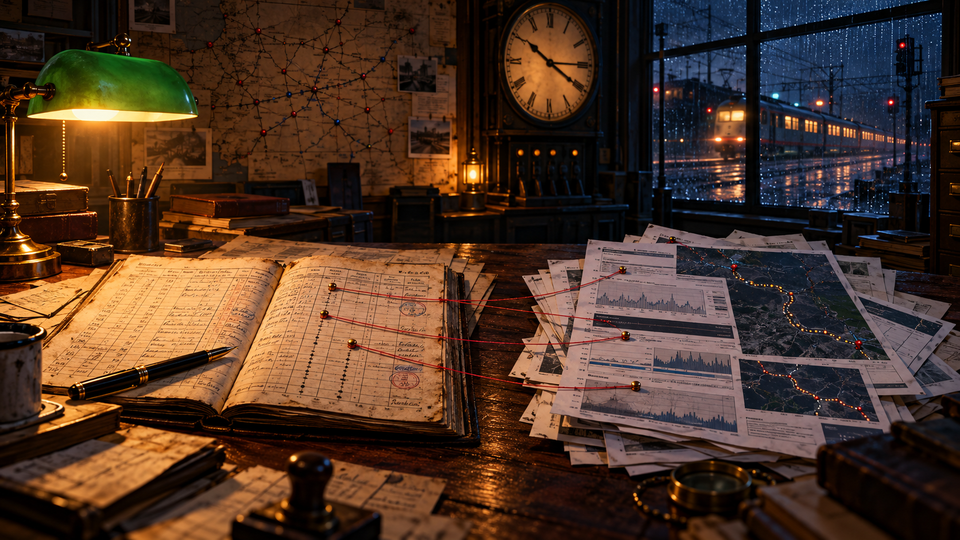

## **Feladatleírás**

Egy hazai vasúttársaságnál minden vonat útját két, egymástól független rendszer rögzíti. A **forgalmi napló** a menetrendből és a diszpécserek jelentéseiből dolgozik: tudja, hány megállója van a vonatnak, mennyi a menetrend szerinti menetideje, és mekkora késéssel indult, illetve érkezett. A **GPS-szolgáltató** csak azt látja, amit a szerelvényre szerelt eszköz nagyjából percenként jelent: mennyi ideig mozgott a vonat, mekkora utat tett meg, hányszor állt meg, és milyen sebességgel haladt.

A két rendszer rekordjait egy közös azonosító kötötte össze. Egy elhibázott adatbázis-migráció során azonban a szeptember 1. utáni rekordok azonosítói elvesztek, a két tábla sorai pedig összekeveredtek. Egyetlen információ maradt meg: minden rekordról tudjuk, melyik nap melyik órájában indult a vonat. A rekordok ennek megfelelően **blokkokba** vannak rendezve. Egy blokk egy adott nap egy adott órájában induló összes utat tartalmazza, a két táblában pontosan ugyanazokat az utakat, csak más sorrendben és más azonosítókkal.

A feladatod, hogy a szeptemberi GPS-rekordok mindegyikéhez megtaláld a forgalmi napló azon bejegyzését, amely ugyanahhoz az úthoz tartozik.

**Amit kapsz:**

* `train.csv`: 59 848 korábbi út (augusztus 14. és szeptember 1. között) 435 blokkban, a napló és a GPS adataival együtt, tehát itt a párok ismertek
* `test_a.csv`: a forgalmi napló szeptemberi bejegyzései (`a_id` azonosítóval), 22 868 sor 156 blokkban
* `test_b.csv`: a GPS-szolgáltató szeptemberi rekordjai (`b_id` azonosítóval), ugyanazok az utak ugyanazokban a blokkokban

**Amit beadsz:** egyetlen `submission.csv` fájl `b_id,a_id` fejléccel, pontosan 22 868 sorral. A `test_b.csv` minden `b_id` azonosítója pontosan egyszer szerepeljen, mellette annak a naplóbejegyzésnek az `a_id` azonosítója, amelyet a GPS-rekord párjának gondolsz.

**Pontozás:** a helyesen párosított GPS-rekordok aránya (pontosság), amelyet a feladatleírásban megadott görbe alakít pontszámmá. A teljes teszthalmazon értékelünk, az eredmény a ranglistán is látszik.

Az oszlopok pontos jelentését a [feladatleírás PDF](https://github.com/hungarian-ai-olympiad/HAIO-Hungarian-AI-Olympiad/blob/main/2026/docs/one-pagerek/teli-orszagos/ml-one-pager.pdf) tartalmazza.

## **Hasznos Linkek**

A versenyen az engedélyezett csomagok offline dokumentációja a géptermi környezetben volt elérhető. Ugyanezek nyilvánosan:

- [NumPy dokumentáció](https://numpy.org/doc/stable/)
- [pandas dokumentáció](https://pandas.pydata.org/docs/)
- [scikit-learn dokumentáció](https://scikit-learn.org/stable/user_guide.html)
- [SciPy: linear_sum_assignment](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html)

## **Szükséges Importok**

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# NE MÓDOSÍTSD: ezzel a seeddel kapod ugyanazt az eredményt minden
# újrafuttatáskor.
# ═══════════════════════════════════════════════════════════════════
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd

# --- Reprodukálhatóság: minden véletlent egyetlen seedhez kötünk ---
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

## **Fájlok betöltése**

A versenyen a három CSV fájlt a DOCK platformról lehetett letölteni. A HAIO GitHub-tárhelyén a notebook mellett, az `adatok/kettos-konyveles/` mappában vannak. A cella egy `data/` mappában, a notebook mellett és ebben a mappában keresi őket, és ha egyik helyen sem találja, letölti őket a tárhelyről a `data/` mappába.

- `train`: tanítóhalmaz, minden sor egy ismert pár (napló és GPS együtt)
- `test_a`: a forgalmi napló tesztrekordjai
- `test_b`: a GPS-szolgáltató tesztrekordjai
- `A_COLS`, `B_COLS`: a napló, illetve a GPS jellemzőinek oszlopnevei

In [ ]:
import urllib.request

FILES = ["train.csv", "test_a.csv", "test_b.csv"]
REPO_DATA = ("https://raw.githubusercontent.com/hungarian-ai-olympiad/HAIO-Hungarian-AI-Olympiad/"
             "main/2026/teli-orszagos/feladatok/adatok/kettos-konyveles")
PLACES = [Path("data"), Path("."), Path("adatok/kettos-konyveles")]

DATA_DIR = next((d for d in PLACES if all((d / f).exists() for f in FILES)), None)
if DATA_DIR is None:
    DATA_DIR = Path("data")
    DATA_DIR.mkdir(exist_ok=True)
    for f in FILES:
        urllib.request.urlretrieve(f"{REPO_DATA}/{f}", DATA_DIR / f)
    print("A CSV fájlokat letöltöttem a data/ mappába.")

train = pd.read_csv(DATA_DIR / "train.csv")
test_a = pd.read_csv(DATA_DIR / "test_a.csv")
test_b = pd.read_csv(DATA_DIR / "test_b.csv")

A_COLS = [c for c in test_a.columns if c not in ("a_id", "block", "hour")]
B_COLS = [c for c in test_b.columns if c not in ("b_id", "block", "hour")]

print(f"train: {train.shape}, test_a: {test_a.shape}, test_b: {test_b.shape}")

In [ ]:
train.head()

In [ ]:
test_a.head()

In [ ]:
test_b.head()

## **Validáció**

A tanítóhalmazból 40 blokkot leválasztunk, és ugyanúgy összekeverjük, mint a tesztet: a napló és a GPS sorai új, véletlen azonosítót kapnak. Így a teszttel azonos helyzetben mérheted a megoldásodat. A `val_key` a helyes párokat tartalmazza.

In [ ]:
rng = np.random.default_rng(SEED)
val_blocks = rng.choice(train.block.unique(), 40, replace=False)

fit = train[~train.block.isin(val_blocks)].reset_index(drop=True)
val = train[train.block.isin(val_blocks)].reset_index(drop=True)

val["a_id"] = rng.permutation(len(val))
val["b_id"] = rng.permutation(len(val))

val_a = val[["a_id", "block", "hour"] + A_COLS].sample(frac=1, random_state=SEED).reset_index(drop=True)
val_b = val[["b_id", "block", "hour"] + B_COLS].sample(frac=1, random_state=SEED + 1).reset_index(drop=True)
val_key = val[["b_id", "a_id"]]

In [ ]:
def accuracy(pred, key):
    """A helyesen párosított b_id-k aránya."""
    m = key.merge(pred, on="b_id", suffixes=("", "_pred"), how="left")
    return (m.a_id == m.a_id_pred).mean()

## **Baseline**

Véletlen párosítás blokkon belül: minden GPS-rekord a saját blokkjának egy véletlen naplóbejegyzését kapja, és minden naplóbejegyzést pontosan egyszer használunk fel. Ez érvényes beadás, de a pontossága nagyjából 1/(blokkméret), ami 0 pontot ér.

In [ ]:
def random_match(a, b, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for block, bb in b.groupby("block"):
        aa = a[a.block == block]
        out.append(pd.DataFrame({"b_id": bb.b_id.values, "a_id": rng.permutation(aa.a_id.values)}))
    return pd.concat(out, ignore_index=True)


print(f"validációs pontosság: {accuracy(random_match(val_a, val_b), val_key):.4f}")

## **Itt kezdődik a te kódod**

In [ ]:
# innentől írd a megoldásodat

# példa beadás: véletlen párosítás blokkon belül
submission = random_match(test_a, test_b)

## **Beadás**

A cella beadás előtt ellenőrzi a formátumot. A hibás formátumú feltöltés is egy kísérletnek számít, ezért csak akkor töltsd fel a fájlt, ha az ellenőrzés hiba nélkül lefutott.

In [ ]:
submission = submission[["b_id", "a_id"]]

assert len(submission) == len(test_b), f"{len(test_b)} sort várunk, {len(submission)} van"
assert submission.b_id.is_unique, "minden b_id pontosan egyszer szerepeljen"
assert set(submission.b_id) == set(test_b.b_id), "a b_id értékek nem egyeznek a test_b.csv azonosítóival"
assert submission.a_id.isin(test_a.a_id).all(), "van olyan a_id, amely nem szerepel a test_a.csv-ben"
assert submission.a_id.notna().all(), "minden b_id mellé kell a_id"

submission.astype("int64").to_csv("submission.csv", index=False)
print("submission.csv elmentve:", submission.shape)

---

## 🎉 Sok sikert!

A `submission.csv` fájlt töltsd fel a **DOCK** platformra. Legfeljebb **15 feltöltési kísérleted** van, és a legjobb beadásod pontszáma számít.

---